# IMPORTS

In [51]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import seaborn as sns
import pandas as pd

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("results/dl_models_results.json")
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


# DATA LOADING

In [38]:
def load_data(file_name, BASE_DIR=DATA_DIR):
    file_path = BASE_DIR / file_name
    data = pd.read_csv(file_path)
    return data

### LOAD THE DATA

In [76]:
usdinr = load_data("DEXINUS.csv")
usdjpy = load_data("DEXJPUS.csv")
usdeur = load_data("DEXUSEU.csv")
repo_rate = load_data("DFF.csv")
treasury_yield = load_data("DGS10.csv")
commodity_prices = load_data("commodity_futures.csv")
india_vix = load_data("VIX_History.csv")
nifty50 = load_data("NIFTY 50_Data.csv")
nifty50pepb = load_data("NIFTY 50 - HistoricalPE_PBDIV_Data.csv")
niftybank = load_data("NIFTY BANK_Data.csv")
niftybankpepb = load_data("NIFTY BANK - HistoricalPE_PBDIV_Data.csv")
india_gold = load_data("Gold price INR.csv")
sap500 = load_data("sap500.csv")

### BASIC EXPLORATION

In [24]:
print("USD/INR Data:")
print(usdinr.head())
print("USD/JPY Data:")
print(usdjpy.head())
print("USD/EUR Data:")
print(usdeur.head())
print("Repo Rate Data:")
print(repo_rate.head())
print("Treasury Yield Data:")
print(treasury_yield.head())
print("Commodity Prices Data:")
print(commodity_prices.head())
print("India VIX Data:")
print(india_vix.head())
print("Nifty 50 Data:")
print(nifty50.head())
print("Nifty Bank Data:")
print(niftybank.head())
print("S&P 500 Data:")
print(sap500.head())

USD/INR Data:
                  DEXINUS
observation_date         
1973-01-02           8.02
1973-01-03           8.02
1973-01-04           8.00
1973-01-05           8.01
1973-01-08           8.00
USD/JPY Data:
                  DEXJPUS
observation_date         
1971-01-04         357.73
1971-01-05         357.81
1971-01-06         357.86
1971-01-07         357.87
1971-01-08         357.82
USD/EUR Data:
                  DEXUSEU
observation_date         
1999-01-04         1.1812
1999-01-05         1.1760
1999-01-06         1.1636
1999-01-07         1.1672
1999-01-08         1.1554
Repo Rate Data:
                   DFF
observation_date      
1954-07-01        1.13
1954-07-02        1.25
1954-07-03        1.25
1954-07-04        1.25
1954-07-05        0.88
Treasury Yield Data:
                  DGS10
observation_date       
1962-01-02         4.06
1962-01-03         4.03
1962-01-04         3.99
1962-01-05         4.02
1962-01-08         4.03
Commodity Prices Data:
            NATURAL GAS

In [34]:
print("\033[1;32m" + "="*30 + " USD/INR Data: " + "="*30 + "\033[0m")
print(usdinr.info())
print(usdinr.describe())
print("\033[1;32m" + "="*30 + " USD/JPY Data: " + "="*30 + "\033[0m")
print(usdjpy.info())
print(usdjpy.describe())
print("\033[1;32m" + "="*30 + " USD/EUR Data: " + "="*30 + "\033[0m")
print(usdeur.info())
print(usdeur.describe())
print("\033[1;32m" + "="*30 + " Repo Rate Data: " + "="*30 + "\033[0m")
print(repo_rate.info())
print(repo_rate.describe())
print("\033[1;32m" + "="*30 + " Treasury Yield Data: " + "="*30 + "\033[0m")
print(treasury_yield.info())
print(treasury_yield.describe())
print("\033[1;32m" + "="*30 + " Commodity Prices Data: " + "="*30 + "\033[0m")
print(commodity_prices.info())
print(commodity_prices.describe())
print("\033[1;32m" + "="*30 + " India VIX Data: " + "="*30 + "\033[0m")
print(india_vix.info())
print(india_vix.describe())
print("\033[1;32m" + "="*30 + " Nifty 50 Data: " + "="*30 + "\033[0m")
print(nifty50.info())
print(nifty50.describe())
print("\033[1;32m" + "="*30 + " Nifty Bank Data: " + "="*30 + "\033[0m")
print(niftybank.info())
print(niftybank.describe())
print("\033[1;32m" + "="*30 + " S&P 500 Data: " + "="*30 + "\033[0m")
print(sap500.info())
print(sap500.describe())

============================== USD/INR Data: ==============================
<class 'pandas.DataFrame'>
DatetimeIndex: 13999 entries, 1973-01-02 to 2026-08-28
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   DEXINUS  13449 non-null  float64
dtypes: float64(1)
memory usage: 218.7 KB
None
            DEXINUS
count  13449.000000
mean      38.951964
std       24.830751
min        7.190000
25%       12.620000
50%       42.500000
75%       55.520000
max       96.820000
============================== USD/JPY Data: ==============================
<class 'pandas.DataFrame'>
DatetimeIndex: 14520 entries, 1971-01-04 to 2026-08-28
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   DEXJPUS  13951 non-null  float64
dtypes: float64(1)
memory usage: 226.9 KB
None
            DEXJPUS
count  13951.000000
mean     156.253188
std       68.875702
min       75.720000
25%      108.63500

### ADD INDEXES

In [77]:
usdinr["observation_date"] = pd.to_datetime(usdinr["observation_date"])
usdinr = usdinr.set_index("observation_date")

usdjpy["observation_date"] = pd.to_datetime(usdjpy["observation_date"])
usdjpy = usdjpy.set_index("observation_date")

usdeur["observation_date"] = pd.to_datetime(usdeur["observation_date"])
usdeur = usdeur.set_index("observation_date")

repo_rate["observation_date"] = pd.to_datetime(repo_rate["observation_date"])
repo_rate = repo_rate.set_index("observation_date")

treasury_yield["observation_date"] = pd.to_datetime(treasury_yield["observation_date"])
treasury_yield = treasury_yield.set_index("observation_date")

commodity_prices["Date"] = pd.to_datetime(commodity_prices["Date"])
commodity_prices = commodity_prices.set_index("Date")

india_vix["Date"] = pd.to_datetime(india_vix["DATE"])
india_vix = india_vix.set_index("Date")

nifty50["Date"] = pd.to_datetime(nifty50["Date"])
nifty50 = nifty50.set_index("Date")

nifty50pepb["Date"] = pd.to_datetime(nifty50pepb["Date"])
nifty50pepb = nifty50pepb.set_index("Date")

niftybank["Date"] = pd.to_datetime(niftybank["Date"])
niftybank = niftybank.set_index("Date")

niftybankpepb["Date"] = pd.to_datetime(niftybankpepb["Date"])
niftybankpepb = niftybankpepb.set_index("Date")

india_gold["Date"] = pd.to_datetime(india_gold["Date"], format="%d/%m/%Y")
india_gold = india_gold.set_index("Date")

sap500["Date"] = pd.to_datetime(sap500["Date"])
sap500 = sap500.set_index("Date")

In [89]:
## MERGE INDEXES AND DATAFRAMES

# USDINR
full_df = usdinr.copy()

# GLOBAL DATA
full_df["jpy"] = usdjpy["DEXJPUS"]
full_df["eur"] = usdeur["DEXUSEU"]
full_df["repo_rate"] = repo_rate["DFF"]
full_df["treasury_yield"] = treasury_yield["DGS10"]

# COMMODITY PRICES GLOBALLY
full_df["gold"] = commodity_prices["GOLD"]
full_df["wti_crude"] = commodity_prices["WTI CRUDE"]
full_df["brent_crude"] = commodity_prices["BRENT CRUDE"]
full_df["soybeans"] = commodity_prices["SOYBEANS"]
full_df["corn"] = commodity_prices["CORN"]
full_df["copper"] = commodity_prices["COPPER"]
full_df["silver"] = commodity_prices["SILVER"]
full_df["low_sulphur_gas_oil"] = commodity_prices["LOW SULPHUR GAS OIL"]
full_df["live_cattle"] = commodity_prices["LIVE CATTLE"]
full_df["soybean_oil"] = commodity_prices["SOYBEAN OIL"]
full_df["aluminium"] = commodity_prices["ALUMINIUM"]
full_df["soybean_meal"] = commodity_prices["SOYBEAN MEAL"]
full_df["zinc"] = commodity_prices["ZINC"]
full_df["uls_diesel"] = commodity_prices["ULS DIESEL"]
full_df["nickel"] = commodity_prices["NICKEL"]
full_df["wheat"] = commodity_prices["WHEAT"]
full_df["sugar"] = commodity_prices["SUGAR"]
# full_df["gasoline"] = commodity_prices["GASOLINE"]
full_df["coffee"] = commodity_prices["COFFEE"]
full_df["lean_hogs"] = commodity_prices["LEAN HOGS"]
full_df["hrw_wheat"] = commodity_prices["HRW WHEAT"]
full_df["cotton"] = commodity_prices["COTTON"]

# INDIA DATA
full_df["india_vix_open"] = india_vix["OPEN"]
full_df["india_vix_high"] = india_vix["HIGH"]
full_df["india_vix_low"] = india_vix["LOW"]
full_df["india_vix_close"] = india_vix["CLOSE"]
full_df["nifty50_open"] = nifty50["Open"]
full_df["nifty50_high"] = nifty50["High"]
full_df["nifty50_low"] = nifty50["Low"]
full_df["nifty50_close"] = nifty50["Close"]
full_df["nifty50_pe"] = nifty50pepb["P/E"]
full_df["nifty50_pb"] = nifty50pepb["P/B"]
full_df["nifty50_div_yield"] = nifty50pepb["Div Yield %"]
# full_df["niftybank_open"] = niftybank["Open"]
# full_df["niftybank_high"] = niftybank["High"]
# full_df["niftybank_low"] = niftybank["Low"]
full_df["niftybank_close"] = niftybank["Close"]
full_df["niftybank_pe"] = niftybankpepb["P/E"]
full_df["niftybank_pb"] = niftybankpepb["P/B"]
full_df["niftybank_div_yield"] = niftybankpepb["Div Yield %"]
full_df["india_gold"] = india_gold["INR"]

# US DATA
full_df["sp500_open"] = sap500["Open"]
full_df["sp500_high"] = sap500["High"]
full_df["sp500_low"] = sap500["Low"]
full_df["sp500_close"] = sap500["Close"]
full_df["sp500_volume"] = sap500["Volume"]

print(full_df.head())


                  DEXINUS     jpy  eur  repo_rate  treasury_yield  gold  \
observation_date                                                          
1973-01-02           8.02  301.39  NaN       6.00            6.43   NaN   
1973-01-03           8.02  301.43  NaN       5.50            6.42   NaN   
1973-01-04           8.00  301.20  NaN       5.75            6.40   NaN   
1973-01-05           8.01  301.30  NaN       5.75            6.42   NaN   
1973-01-08           8.00  302.21  NaN       5.63            6.43   NaN   

                  wti_crude  brent_crude  soybeans  corn  ...  \
observation_date                                          ...   
1973-01-02              NaN          NaN       NaN   NaN  ...   
1973-01-03              NaN          NaN       NaN   NaN  ...   
1973-01-04              NaN          NaN       NaN   NaN  ...   
1973-01-05              NaN          NaN       NaN   NaN  ...   
1973-01-08              NaN          NaN       NaN   NaN  ...   

                  

### DATA CLEANING

In [90]:
# Keep observations from 1 January 2000 onward before handling missing values.
full_df = full_df.loc[
    full_df.index.to_series().between("2000-01-01", "2021-12-31")
].copy()

print(f"Shape after restricting data to 2000 onward: {full_df.shape}")
missing_summary = (
    full_df.isna()
    .sum()
    .sort_values(ascending=False)
    .rename("missing_values")
    .to_frame()
    .assign(
        missing_percent=lambda frame: (
            frame["missing_values"] / len(full_df) * 100
        ).round(2)
    )
)
missing_summary = missing_summary[missing_summary["missing_values"] > 0]

print("Columns with missing values:")
display(missing_summary)

Shape after restricting data to 2000 onward: (5740, 47)
Columns with missing values:


,missing_values,missing_percent
niftybank_pb,291,5.07
nifty50_pe,291,5.07
niftybank_pe,291,5.07
niftybank_div_yield,291,5.07
nifty50_pb,291,5.07
nifty50_div_yield,291,5.07
nifty50_open,290,5.05
nifty50_close,290,5.05
nifty50_high,290,5.05
niftybank_close,290,5.05


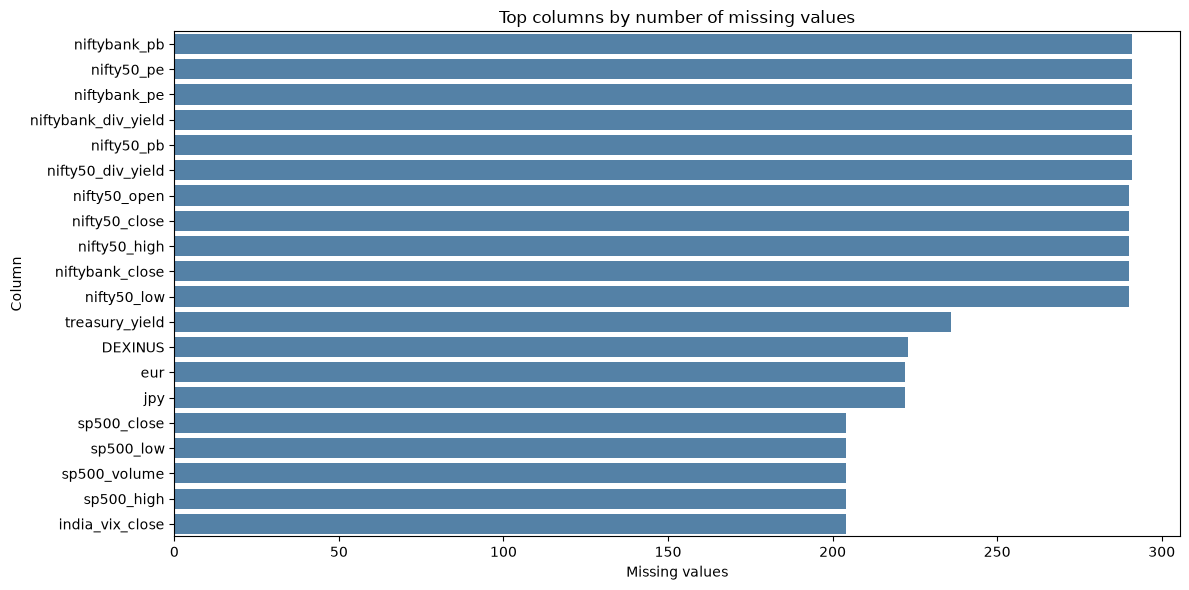

In [91]:
if missing_summary.empty:
    print("No missing values found after filtering to 2000 onward.")
else:
    top_missing = missing_summary.head(20)
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=top_missing["missing_values"],
        y=top_missing.index,
        color="steelblue",
    )
    plt.title("Top columns by number of missing values")
    plt.xlabel("Missing values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()

<Axes: title={'center': 'India VIX Close Price Over Time'}, xlabel='observation_date'>

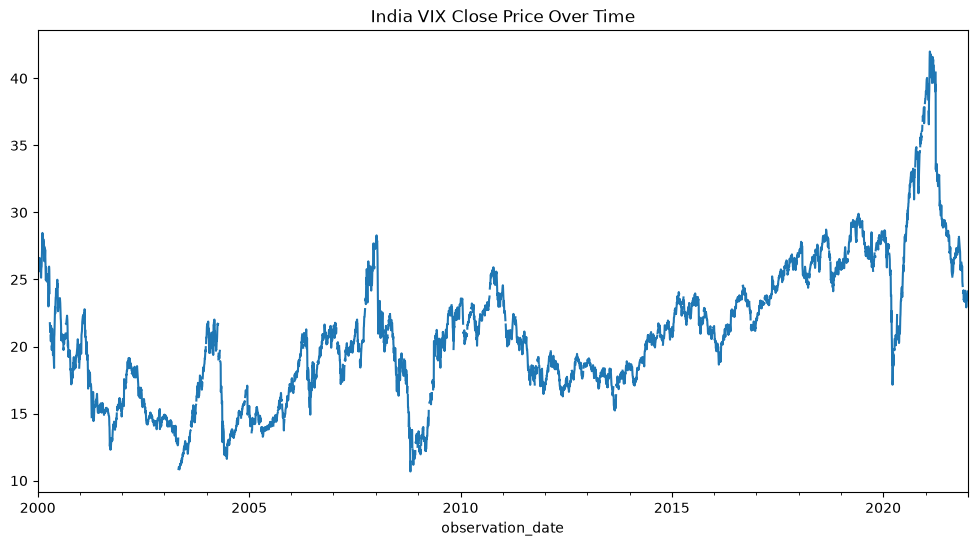

In [96]:
full_df["nifty50_pe"].plot(figsize=(12, 6), title="India VIX Close Price Over Time")

In [94]:
missing_summary = (
    full_df.isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_summary[missing_summary > 0])

niftybank_pb           291
nifty50_pe             291
niftybank_pe           291
niftybank_div_yield    291
nifty50_pb             291
nifty50_div_yield      291
nifty50_open           290
nifty50_close          290
nifty50_high           290
niftybank_close        290
nifty50_low            290
treasury_yield         236
DEXINUS                223
eur                    222
jpy                    222
sp500_close            204
sp500_low              204
sp500_volume           204
sp500_high             204
india_vix_close        204
sp500_open             204
india_vix_open         204
india_vix_high         204
india_vix_low          204
brent_crude             62
gold                    62
wti_crude               62
aluminium               62
silver                  62
copper                  62
low_sulphur_gas_oil     62
uls_diesel              62
soybean_meal            61
soybeans                61
live_cattle             61
corn                    61
soybean_oil             61
h

In [97]:
missing_dates = full_df.index[full_df.isna().any(axis=1)]

missing_date_analysis = pd.DataFrame(index=missing_dates)
missing_date_analysis["day_name"] = missing_date_analysis.index.day_name()
missing_date_analysis["is_weekend"] = (
    missing_date_analysis.index.dayofweek >= 5
)

print("Missing dates:", len(missing_date_analysis))
print("\nMissing dates by weekday:")
display(missing_date_analysis["day_name"].value_counts())

print("\nWeekend missing dates:")
print(missing_date_analysis["is_weekend"].sum())

print("\nMissing dates by month:")
display(missing_date_analysis.index.month.value_counts().sort_index())

Missing dates: 504

Missing dates by weekday:


day_name
Monday       189
Friday        97
Thursday      89
Wednesday     65
Tuesday       64
Name: count, dtype: int64


Weekend missing dates:
0

Missing dates by month:


observation_date
1     65
2     34
3     36
4     52
5     42
6      3
7     26
8     25
9     43
10    69
11    74
12    35
Name: count, dtype: int64

In [98]:
missing_dates = pd.Series(
    full_df.index[full_df.isna().any(axis=1)]
).sort_values()

missing_date_gaps = missing_dates.diff().dt.days

print("Largest gaps between missing dates:")
display(missing_date_gaps.sort_values(ascending=False).head(20))

Largest gaps between missing dates:


468    66.0
206    66.0
346    66.0
94     63.0
229    63.0
227    47.0
109    46.0
16     45.0
28     42.0
178    42.0
158    42.0
137    42.0
414    42.0
52     42.0
11     42.0
247    42.0
270    42.0
74     42.0
394    42.0
242    41.0
Name: observation_date, dtype: float64